In [112]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.datasets import make_moons


In [113]:
D = 2
N = 2_000
SEED = 42
DEVICE = 'cpu'

steps = 1000
batch_size = 256
lr = 1e-3
eps_max = 0.05

np.random.seed(SEED)
torch.manual_seed(SEED)

In [114]:
def sample_data(batch_size,):
    X, y = make_moons(batch_size, noise=0.1, random_state=SEED)
    return torch.from_numpy(X).float()

def sample_noise(batch_size, n_modes=8, radius=2.0, std=0.1):
    angles = torch.randint(0, n_modes, (batch_size,)).float() * (2 * 3.14159265 / n_modes)
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1) + 0.5
    return centers + std * torch.randn(batch_size, 2)

In [ ]:
class FlowMatching(nn.Module):
    def __init__(self, dim = 2, hidden_dim = 64):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim + 1, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.SiLU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, t, x_t):
        tx = torch.cat([t, x_t], dim=-1)
        return self.net(tx)

def interpolate_linear(x_0, x_1, t):
    x_t = ((1 - t) * x_0) + (t * x_1)
    return x_t

def get_target_velocity(x_0, x_1):
    return x_1 - x_0

def loss(fmm):
    x_0 = sample_noise(batch_size)
    x_1 = sample_data(batch_size)

    t = torch.rand(x_1.shape[0], device=DEVICE).unsqueeze(-1)

    x_t = interpolate_linear(x_0, x_1, t)
    v_target = get_target_velocity(x_0, x_1)
    v_pred = fmm(t, x_t)

    loss = ((v_pred - v_target)**2).mean()

    return loss

In [116]:
fmm = FlowMatching()
opt = torch.optim.Adam(fmm.parameters(), lr)

losses = []

with tqdm(range(steps)) as pb:
    for i in pb:
        opt.zero_grad()
        l = loss(fmm)
        l.backward()
        opt.step()

        pb.set_postfix({'Loss': f'{l.item():.2f}'})
        losses.append(l.item())

100%|██████████| 1000/1000 [00:01<00:00, 672.97it/s, Loss=1.03]


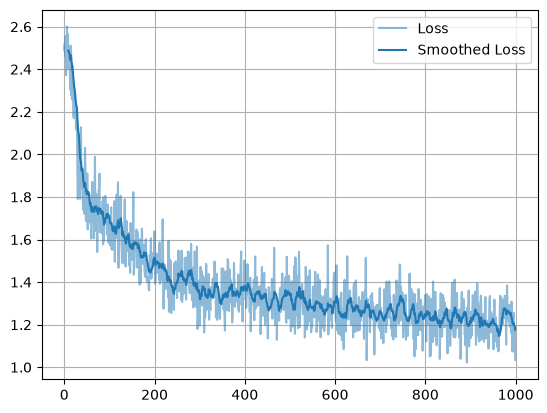

In [117]:
fig, ax = plt.subplots()

ax.plot(losses, label="Loss", color="tab:blue", alpha=0.5)
ws = 10
smoothed = np.convolve(losses, np.ones(ws)/ws, mode="valid")
ax.plot(np.arange(ws-1, len(losses)), smoothed, label="Smoothed Loss", color="tab:blue")

plt.legend()
plt.grid()
plt.show()

In [118]:
@torch.no_grad()
def sample(fmm, n_samples, n_steps = 100):
    x = sample_noise(n_samples).to(DEVICE)
    dt = 1.0 / n_steps

    for i in range(n_steps):
        t_val = i * dt
        t = torch.full((x.shape[0], 1), t_val, device=DEVICE)
        v = fmm(t, x)
        x = x + v * dt

    return x

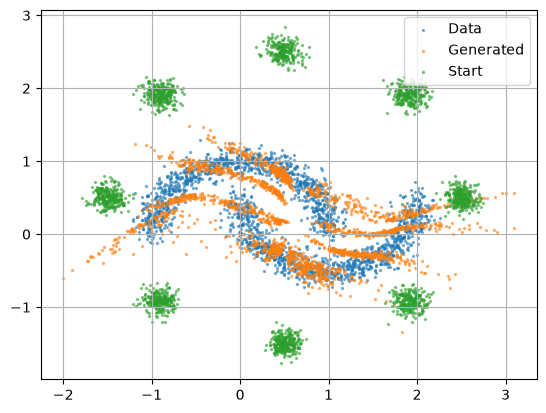

In [119]:
fmm.eval()

data = sample_data(N)
samples = sample(fmm, n_samples=N, n_steps=100)
blobs = sample_noise(N)

fig, ax = plt.subplots()

ax.scatter(data[:, 0], data[:, 1], alpha=0.5, s=2, label="Data")
ax.scatter(samples[:, 0], samples[:, 1], alpha=0.5, s=2, label="Generated")
ax.scatter(blobs[:, 0], blobs[:, 1], alpha=0.5, s=2, label="Start")

plt.legend()
plt.grid()
plt.show()

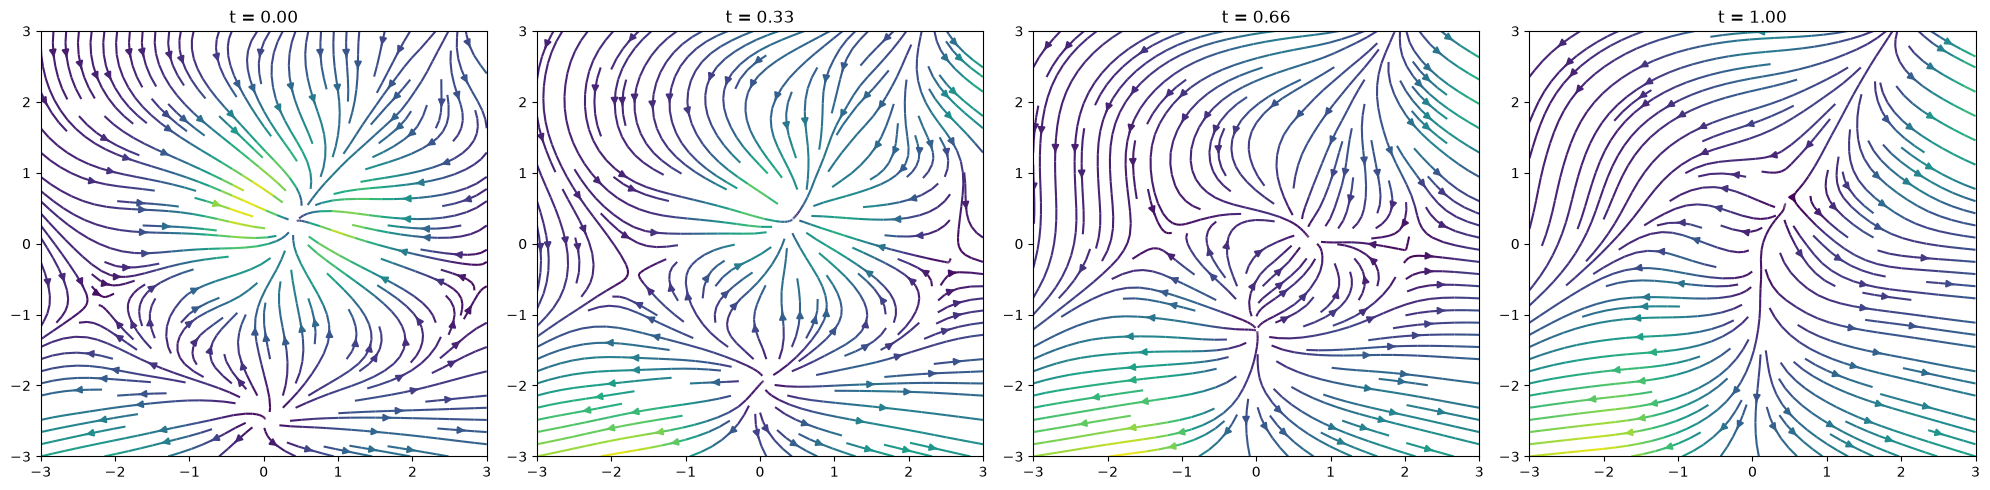

In [120]:
@torch.no_grad()
def plot_vector_field(ax, fmm, t_val, x_range=(-3, 3), y_range=(-3, 3), n_grid=20, device=DEVICE, streamplot=False):
    fmm.eval()

    xs = np.linspace(*x_range, n_grid)
    ys = np.linspace(*y_range, n_grid)
    xx, yy = np.meshgrid(xs, ys)

    grid = torch.tensor(
        np.stack([xx.ravel(), yy.ravel()], axis=1), dtype=torch.float32
    ).to(device)
    t = torch.full((grid.shape[0], 1), t_val, device=device)

    v = fmm(t, grid).cpu().numpy()
    u = v[:, 0].reshape(n_grid, n_grid)
    w = v[:, 1].reshape(n_grid, n_grid)

    if streamplot:
        # streamplot wants strictly increasing 1D x/y, not meshgrid
        ax.streamplot(xx, yy, u, w, color=np.hypot(u, w), cmap="viridis", density=1.2)
    else:
        speed = np.hypot(u, w)
        ax.quiver(xx, yy, u, w, speed, cmap="viridis")

    ax.set_title(f"t = {t_val:.2f}")
    ax.set_xlim(*x_range)
    ax.set_ylim(*y_range)


fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, t_val in zip(axes, [0.0, 0.33, 0.66, 1.0]):
    plot_vector_field(ax, fmm, t_val, streamplot=True)
plt.tight_layout()
plt.show()